In [2]:
import pandas as pd
import xml.etree.ElementTree as ET
from seaborn import boxplot
from matplotlib.pyplot import scatter
from seaborn import heatmap
from phik import phik_matrix

In [3]:
tree = ET.parse("raw_data/restaurants_trial_russian_raw.xml")
root = tree.getroot()
root.tag

'Reviews'

In [4]:
reviews: list = root.findall("Review")
reviews_count: int = len(reviews)
reviews_count

5

In [5]:
sentences_data = []
opinions_data = []

In [6]:
for review in reviews:
    rid = review.get("rid")
    sentences = review.find("sentences")

    if sentences is not None:
        sentences = sentences.findall("sentence")

        for sentence in sentences:
            sentence_id = sentence.get("id")
            sentence_text = sentence.find("text").text
            sentences_data.append({
                "review_id": rid,
                "sentence_id": sentence_id,
                "text": sentence_text
            })

            opinions = sentence.find("Opinions")

            if opinions is not None:

                opinions = opinions.findall("Opinion")
                opinions_count = len(opinions)

                for opinion in opinions:
                    category = opinion.get("category")
                    polarity = opinion.get("polarity")
                    target = opinion.get("target")
                    opinions_data.append({
                        "sentence_id": sentence_id,
                        "category": category,
                        "polarity": polarity,
                        "target": target
                    })



In [7]:
sentences_df = pd.DataFrame(sentences_data)
opinions_df = pd.DataFrame(opinions_data)

In [8]:
sentences_df

,review_id,sentence_id,text
0,3976,3976:0,"День 8-го марта прошёл, можно и итоги подвести."
1,3976,3976:1,Решил написать отзыв о ресторане в котором отм...
2,3976,3976:2,Но теперь о ресторане.
3,3976,3976:3,Столик бронировали заранее и сделали так как п...
4,3976,3976:4,Меню достаточно разнообразное и весьма вкусное...
5,3976,3976:5,Обслуживание может и не самое лучьшее в городе...
6,3976,3976:6,Должен сказать что ждать нам всёравно пришлось...
7,3976,3976:7,"Интерьер хороший, удобные диваны."
8,3976,3976:8,Очень хорошая музыкальная программа и весёлый ...
9,3976,3976:9,"В общем я остался доволен своим выбором, и тем..."


In [9]:
opinions_df

,sentence_id,category,polarity,target
0,3976:1,RESTAURANT#GENERAL,positive,ресторане
1,3976:3,SERVICE#GENERAL,positive,администратор
2,3976:3,SERVICE#GENERAL,positive,предварительный заказ
3,3976:4,FOOD#QUALITY,positive,Меню
4,3976:4,FOOD#STYLE_OPTIONS,positive,Меню
...,...,...,...,...
76,6668:13,SERVICE#GENERAL,neutral,официант
77,6668:14,RESTAURANT#GENERAL,positive,квартиру
78,6668:15,SERVICE#GENERAL,positive,персоналу
79,6668:15,RESTAURANT#GENERAL,positive,ресторана


In [10]:
sentences_df.shape

(60, 3)

In [11]:
opinions_df.shape

(81, 4)

In [12]:
merged_df = sentences_df.merge(opinions_df, how="left", on="sentence_id")
merged_df

,review_id,sentence_id,text,category,polarity,target
0,3976,3976:0,"День 8-го марта прошёл, можно и итоги подвести.",NaN,NaN,NaN
1,3976,3976:1,Решил написать отзыв о ресторане в котором отм...,RESTAURANT#GENERAL,positive,ресторане
2,3976,3976:2,Но теперь о ресторане.,NaN,NaN,NaN
3,3976,3976:3,Столик бронировали заранее и сделали так как п...,SERVICE#GENERAL,positive,администратор
4,3976,3976:3,Столик бронировали заранее и сделали так как п...,SERVICE#GENERAL,positive,предварительный заказ
...,...,...,...,...,...,...
85,6668,6668:13,"Порции не огромные, но и не маленькие, мы наел...",SERVICE#GENERAL,neutral,официант
86,6668,6668:14,"Так что, у нас есть повод придти в квартиру ещ...",RESTAURANT#GENERAL,positive,квартиру
87,6668,6668:15,"Хочу сказать большое спасибо ""ночному персонал...",SERVICE#GENERAL,positive,персоналу
88,6668,6668:15,"Хочу сказать большое спасибо ""ночному персонал...",RESTAURANT#GENERAL,positive,ресторана


In [13]:
print(f"Количество предложений: {sentences_df["sentence_id"].count()}")
print(f"Количество мнений: {opinions_df["sentence_id"].count()}")
print(f"Количество уникальных отзывов: {sentences_df["review_id"].nunique()}")
print(f"Количество предложений с мнениями: {opinions_df["sentence_id"].nunique()}")
print(f"Количество предложений без мнений: {merged_df["category"].isna().sum()}")
print(f"Пропуски по каждому признаку: \n{merged_df.isna().sum()}")


Количество предложений: 60
Количество мнений: 81
Количество уникальных отзывов: 5
Количество предложений с мнениями: 51
Количество предложений без мнений: 9
Пропуски по каждому признаку: 
review_id      0
sentence_id    0
text           0
category       9
polarity       9
target         9
dtype: int64


In [14]:
opinions_df["general_category"] = opinions_df["category"].apply(lambda string: string[:string.find("#")])
opinions_df

,sentence_id,category,polarity,target,general_category
0,3976:1,RESTAURANT#GENERAL,positive,ресторане,RESTAURANT
1,3976:3,SERVICE#GENERAL,positive,администратор,SERVICE
2,3976:3,SERVICE#GENERAL,positive,предварительный заказ,SERVICE
3,3976:4,FOOD#QUALITY,positive,Меню,FOOD
4,3976:4,FOOD#STYLE_OPTIONS,positive,Меню,FOOD
...,...,...,...,...,...
76,6668:13,SERVICE#GENERAL,neutral,официант,SERVICE
77,6668:14,RESTAURANT#GENERAL,positive,квартиру,RESTAURANT
78,6668:15,SERVICE#GENERAL,positive,персоналу,SERVICE
79,6668:15,RESTAURANT#GENERAL,positive,ресторана,RESTAURANT


In [15]:
opinions_categories_val_counts = opinions_df["category"].value_counts()
opinions_categories_val_counts

category
SERVICE#GENERAL       24
RESTAURANT#GENERAL    14
FOOD#QUALITY          13
AMBIENCE#GENERAL      12
FOOD#STYLE_OPTIONS     8
RESTAURANT#PRICES      2
FOOD#PRICES            2
LOCATION#GENERAL       2
DRINK#QUALITY          2
DRINK#PRICES           1
FOOD#GENERAL           1
Name: count, dtype: int64

<Axes: xlabel='general_category'>

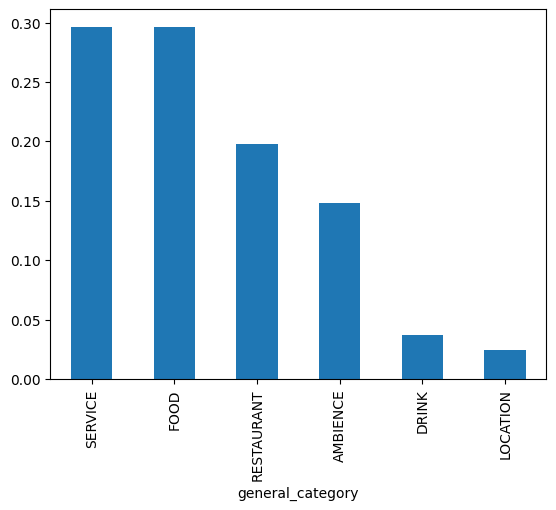

In [16]:
opinions_general_categories_val_counts = opinions_df["general_category"].value_counts(normalize=True)
opinions_general_categories_val_counts.plot.bar()

In [17]:
opinions_unique_categories = opinions_df["category"].unique()
opinions_general_categories = opinions_df["category"].apply(lambda string: string[:string.find("#")]).unique()

print(f"Уникальные категории: {opinions_unique_categories}")
print(f"Общие уникальные категории: {opinions_general_categories}")

Уникальные категории: ['RESTAURANT#GENERAL' 'SERVICE#GENERAL' 'FOOD#QUALITY'
 'FOOD#STYLE_OPTIONS' 'AMBIENCE#GENERAL' 'RESTAURANT#PRICES' 'FOOD#PRICES'
 'LOCATION#GENERAL' 'DRINK#QUALITY' 'DRINK#PRICES' 'FOOD#GENERAL']
Общие уникальные категории: ['RESTAURANT' 'SERVICE' 'FOOD' 'AMBIENCE' 'LOCATION' 'DRINK']


<Axes: xlabel='polarity'>

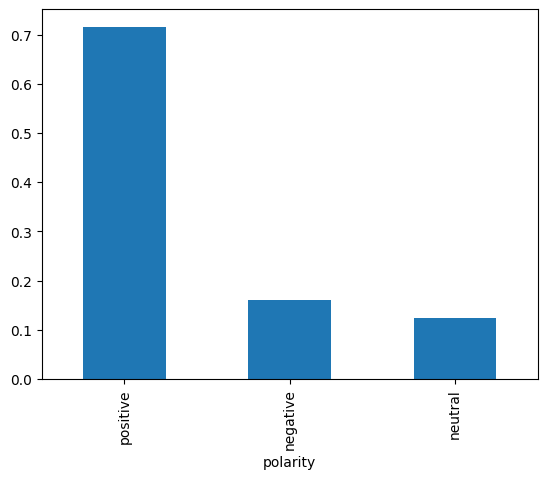

In [18]:
opinions_polarity_val_counts = opinions_df["polarity"].value_counts(normalize=True)
opinions_polarity_val_counts.plot.bar()

In [19]:
polarity_count = opinions_df["polarity"].count()
polarity_positive_count = opinions_df[opinions_df.loc[:, "polarity"] == "positive"]["polarity"].count()
polarity_negative_count = opinions_df[opinions_df.loc[:, "polarity"] == "negative"]["polarity"].count()
polarity_neutral_count = opinions_df[opinions_df.loc[:, "polarity"] == "neutral"]["polarity"].count()

print(f"Доля положительных отзывов: {polarity_positive_count / polarity_count}")
print(f"Доля негативных отзывов: {polarity_negative_count / polarity_count}")
print(f"Доля нейтральных отзывов: {polarity_neutral_count / polarity_count}")

Доля положительных отзывов: 0.7160493827160493
Доля негативных отзывов: 0.16049382716049382
Доля нейтральных отзывов: 0.12345679012345678


<Axes: ylabel='general_category'>

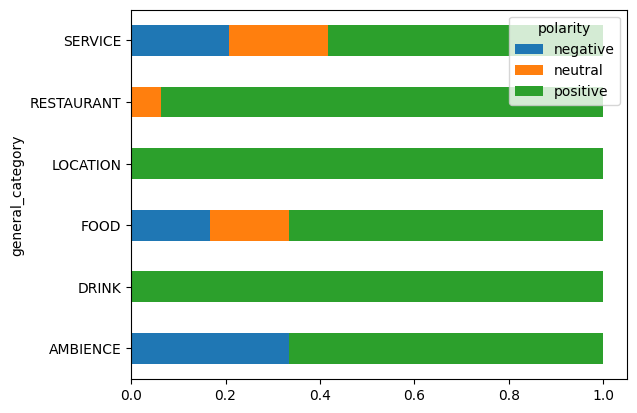

In [20]:
polarity_counts_df = pd.crosstab(opinions_df["general_category"], opinions_df["polarity"])
polarity_share_df = pd.crosstab(opinions_df["general_category"], opinions_df["polarity"], normalize="index")
polarity_share_df.plot.barh(stacked=True)

In [21]:
polarity_counts_df

polarity,negative,neutral,positive
general_category,,,
AMBIENCE,4,0,8
DRINK,0,0,3
FOOD,4,4,16
LOCATION,0,0,2
RESTAURANT,0,1,15
SERVICE,5,5,14


In [22]:
sentences_df["char_count"] = sentences_df["text"].str.len()
sentences_df["words_count"] = sentences_df["text"].str.split().str.len()
sentences_df

,review_id,sentence_id,text,char_count,words_count
0,3976,3976:0,"День 8-го марта прошёл, можно и итоги подвести.",47,8
1,3976,3976:1,Решил написать отзыв о ресторане в котором отм...,195,28
2,3976,3976:2,Но теперь о ресторане.,22,4
3,3976,3976:3,Столик бронировали заранее и сделали так как п...,296,39
4,3976,3976:4,Меню достаточно разнообразное и весьма вкусное...,123,19
5,3976,3976:5,Обслуживание может и не самое лучьшее в городе...,82,14
6,3976,3976:6,Должен сказать что ждать нам всёравно пришлось...,82,13
7,3976,3976:7,"Интерьер хороший, удобные диваны.",33,4
8,3976,3976:8,Очень хорошая музыкальная программа и весёлый ...,54,7
9,3976,3976:9,"В общем я остался доволен своим выбором, и тем...",110,19


In [23]:
sentences_df.describe()

,char_count,words_count
count,60.000000,60.000000
mean,80.900000,11.433333
std,63.995683,8.383532
min,8.000000,1.000000
25%,42.250000,6.000000
50%,62.500000,9.000000
75%,103.250000,14.000000
max,301.000000,39.000000


<Axes: >

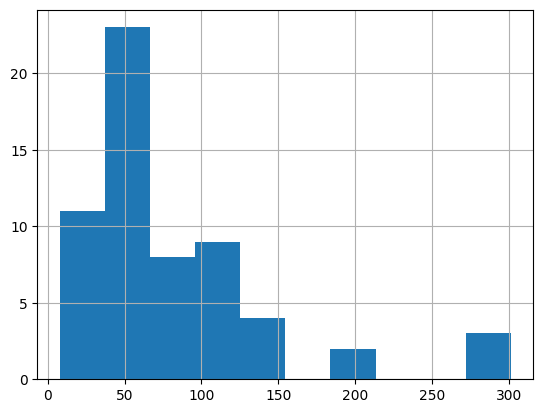

In [24]:
sentences_df["char_count"].hist()

<Axes: >

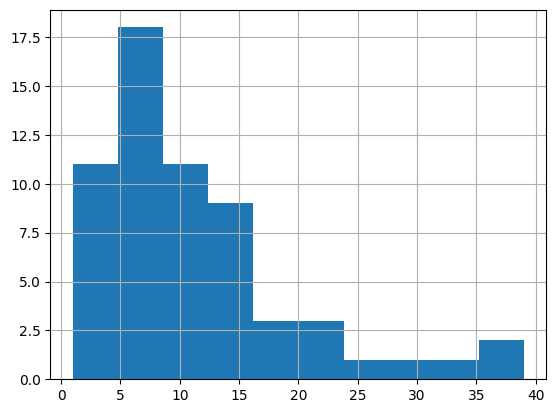

In [25]:
sentences_df["words_count"].hist()


<Axes: ylabel='char_count'>

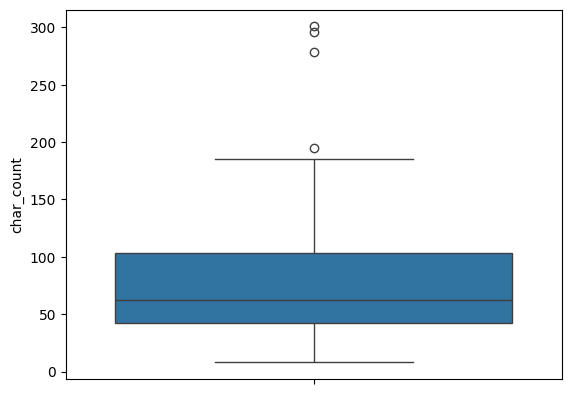

In [26]:
boxplot(sentences_df["char_count"]) #type: ignore

<Axes: ylabel='words_count'>

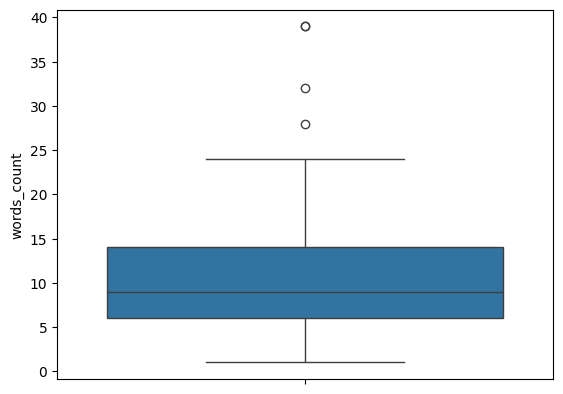

In [27]:
boxplot(sentences_df["words_count"]) #type: ignore


In [28]:
sentences_df.sort_values(by="words_count", ascending=False)

,review_id,sentence_id,text,char_count,words_count
3,3976,3976:3,Столик бронировали заранее и сделали так как п...,296,39
41,35867,35867:3,Отдельно благодарим ЗАМЕЧАТЕЛЬНОГО менеджера п...,301,39
39,35867,35867:1,Выбор был сделан по нескольким качествам данно...,279,32
1,3976,3976:1,Решил написать отзыв о ресторане в котором отм...,195,28
57,6668,6668:13,"Порции не огромные, но и не маленькие, мы наел...",136,24
51,6668,6668:7,"Правда, заказ принесли не быстро, хотя кроме н...",127,23
12,30808,30808:1,Хочу выразить большую благодарность прежде все...,185,22
25,16137,16137:7,Не дождавшись хоть какого-то внимания в наш ад...,143,20
9,3976,3976:9,"В общем я остался доволен своим выбором, и тем...",110,19
4,3976,3976:4,Меню достаточно разнообразное и весьма вкусное...,123,19


In [29]:
q3_char_count = sentences_df["char_count"].quantile(0.75)
q1_char_count = sentences_df["char_count"].quantile(0.25)
iqr_char_count = q3_char_count - q1_char_count
outliers_upper_bound_char_count = q3_char_count + 1.5 * iqr_char_count
outliers_lower_bound_char_count = q1_char_count - 1.5 * iqr_char_count
sentences_df[(sentences_df["char_count"] > outliers_upper_bound_char_count) | (sentences_df["char_count"] < outliers_lower_bound_char_count)]


,review_id,sentence_id,text,char_count,words_count
1,3976,3976:1,Решил написать отзыв о ресторане в котором отм...,195,28
3,3976,3976:3,Столик бронировали заранее и сделали так как п...,296,39
39,35867,35867:1,Выбор был сделан по нескольким качествам данно...,279,32
41,35867,35867:3,Отдельно благодарим ЗАМЕЧАТЕЛЬНОГО менеджера п...,301,39


In [30]:
q3_words_count = sentences_df["words_count"].quantile(0.75)
q1_words_count = sentences_df["words_count"].quantile(0.25)
iqr_words_count = q3_words_count - q1_words_count
outliers_upper_bound_words_count = q3_words_count + 1.5 * iqr_words_count
outliers_lower_bound_words_count = q1_words_count - 1.5 * iqr_words_count
sentences_df[sentences_df["words_count"] > outliers_upper_bound_words_count]

,review_id,sentence_id,text,char_count,words_count
1,3976,3976:1,Решил написать отзыв о ресторане в котором отм...,195,28
3,3976,3976:3,Столик бронировали заранее и сделали так как п...,296,39
39,35867,35867:1,Выбор был сделан по нескольким качествам данно...,279,32
41,35867,35867:3,Отдельно благодарим ЗАМЕЧАТЕЛЬНОГО менеджера п...,301,39


In [31]:
new_merged_df = pd.merge(sentences_df, opinions_df, how="left", on="sentence_id")
new_merged_df

,review_id,sentence_id,text,char_count,words_count,category,polarity,target,general_category
0,3976,3976:0,"День 8-го марта прошёл, можно и итоги подвести.",47,8,NaN,NaN,NaN,NaN
1,3976,3976:1,Решил написать отзыв о ресторане в котором отм...,195,28,RESTAURANT#GENERAL,positive,ресторане,RESTAURANT
2,3976,3976:2,Но теперь о ресторане.,22,4,NaN,NaN,NaN,NaN
3,3976,3976:3,Столик бронировали заранее и сделали так как п...,296,39,SERVICE#GENERAL,positive,администратор,SERVICE
4,3976,3976:3,Столик бронировали заранее и сделали так как п...,296,39,SERVICE#GENERAL,positive,предварительный заказ,SERVICE
...,...,...,...,...,...,...,...,...,...
85,6668,6668:13,"Порции не огромные, но и не маленькие, мы наел...",136,24,SERVICE#GENERAL,neutral,официант,SERVICE
86,6668,6668:14,"Так что, у нас есть повод придти в квартиру ещ...",52,11,RESTAURANT#GENERAL,positive,квартиру,RESTAURANT
87,6668,6668:15,"Хочу сказать большое спасибо ""ночному персонал...",107,14,SERVICE#GENERAL,positive,персоналу,SERVICE
88,6668,6668:15,"Хочу сказать большое спасибо ""ночному персонал...",107,14,RESTAURANT#GENERAL,positive,ресторана,RESTAURANT


In [32]:
new_merged_df_opinions_counts = opinions_df["sentence_id"].value_counts(dropna=False)
sentences_df["opinion_count"] = sentences_df["sentence_id"].map(new_merged_df_opinions_counts).fillna(0)
sentences_df

,review_id,sentence_id,text,char_count,words_count,opinion_count
0,3976,3976:0,"День 8-го марта прошёл, можно и итоги подвести.",47,8,0.0
1,3976,3976:1,Решил написать отзыв о ресторане в котором отм...,195,28,1.0
2,3976,3976:2,Но теперь о ресторане.,22,4,0.0
3,3976,3976:3,Столик бронировали заранее и сделали так как п...,296,39,2.0
4,3976,3976:4,Меню достаточно разнообразное и весьма вкусное...,123,19,2.0
5,3976,3976:5,Обслуживание может и не самое лучьшее в городе...,82,14,1.0
6,3976,3976:6,Должен сказать что ждать нам всёравно пришлось...,82,13,1.0
7,3976,3976:7,"Интерьер хороший, удобные диваны.",33,4,2.0
8,3976,3976:8,Очень хорошая музыкальная программа и весёлый ...,54,7,2.0
9,3976,3976:9,"В общем я остался доволен своим выбором, и тем...",110,19,3.0


In [33]:
opinions_df["sentence_id"].count() == sentences_df["opinion_count"].sum()

np.True_

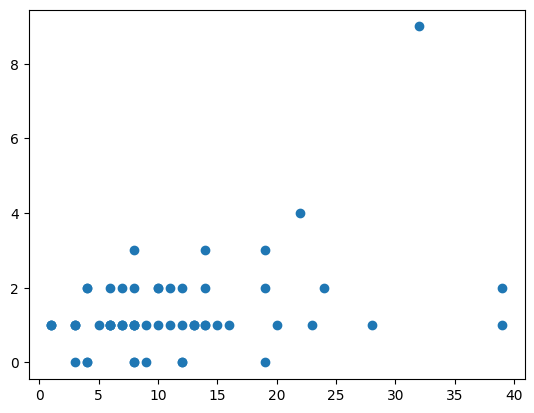

In [34]:
scatter(sentences_df["words_count"], sentences_df["opinion_count"])

<Axes: >

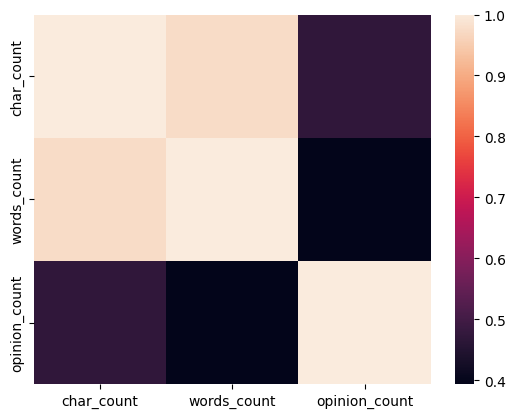

In [39]:
heatmap(sentences_df[["char_count", "words_count", "opinion_count"]].corr("pearson"))

In [40]:
sentences_df[["char_count", "words_count", "opinion_count"]].corr("pearson")

,char_count,words_count,opinion_count
char_count,1.000000,0.975438,0.469554
words_count,0.975438,1.000000,0.393421
opinion_count,0.469554,0.393421,1.000000


<Axes: >

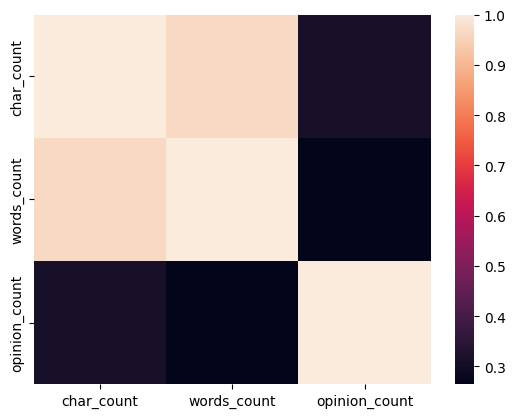

In [41]:
heatmap(sentences_df[["char_count", "words_count", "opinion_count"]].corr("spearman"))

In [42]:
sentences_df[["char_count", "words_count", "opinion_count"]].corr("spearman")

,char_count,words_count,opinion_count
char_count,1.000000,0.964511,0.311501
words_count,0.964511,1.000000,0.264491
opinion_count,0.311501,0.264491,1.000000


interval columns not set, guessing: ['char_count', 'words_count', 'opinion_count']


<Axes: >

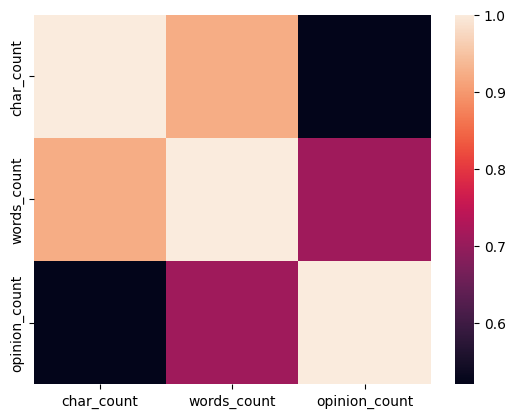

In [44]:
heatmap(phik_matrix(sentences_df[["char_count", "words_count", "opinion_count"]]))

In [45]:
phik_matrix(sentences_df[["char_count", "words_count", "opinion_count"]])

interval columns not set, guessing: ['char_count', 'words_count', 'opinion_count']


,char_count,words_count,opinion_count
char_count,1.000000,0.922639,0.520252
words_count,0.922639,1.000000,0.709780
opinion_count,0.520252,0.709780,1.000000


In [38]:
sentences_df_without_outliers = sentences_df.drop(39)
sentences_df_without_outliers.sort_values(by="opinion_count", ascending=False)

,review_id,sentence_id,text,char_count,words_count,opinion_count
12,30808,30808:1,Хочу выразить большую благодарность прежде все...,185,22,4.0
9,3976,3976:9,"В общем я остался доволен своим выбором, и тем...",110,19,3.0
59,6668,6668:15,"Хочу сказать большое спасибо ""ночному персонал...",107,14,3.0
50,6668,6668:6,"Помогли с заказом, посоветовали хорошее и недо...",57,8,3.0
10,3976,3976:10,Руководству и персоналу СПАСИБО.,32,4,2.0
8,3976,3976:8,Очень хорошая музыкальная программа и весёлый ...,54,7,2.0
7,3976,3976:7,"Интерьер хороший, удобные диваны.",33,4,2.0
17,30808,30808:6,"Хочу отметить, что для ресторана такого уровня...",63,10,2.0
24,16137,16137:6,Во-вторых: Встреча гостей в ресторане- отсутст...,121,14,2.0
4,3976,3976:4,Меню достаточно разнообразное и весьма вкусное...,123,19,2.0


<Axes: >

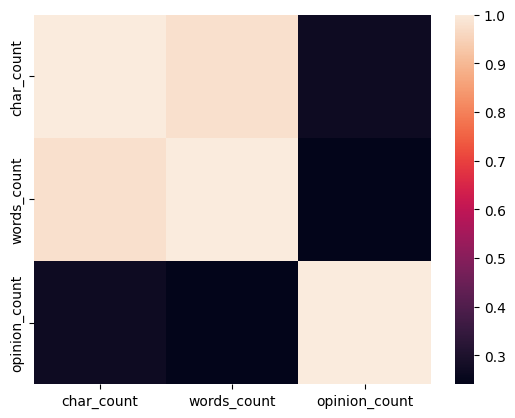

In [46]:
heatmap(sentences_df_without_outliers[["char_count", "words_count", "opinion_count"]].corr("pearson"))

In [47]:
sentences_df_without_outliers[["char_count", "words_count", "opinion_count"]].corr("pearson")

,char_count,words_count,opinion_count
char_count,1.000000,0.976345,0.268135
words_count,0.976345,1.000000,0.240531
opinion_count,0.268135,0.240531,1.000000


<Axes: >

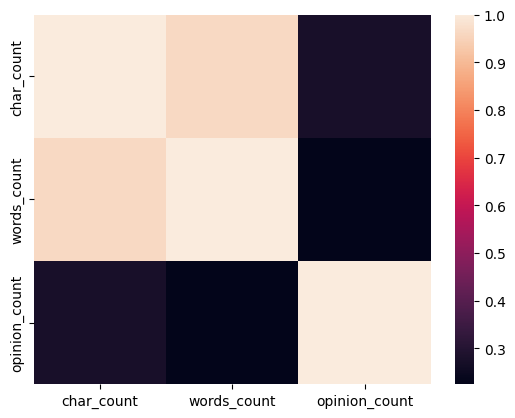

In [48]:
heatmap(sentences_df_without_outliers[["char_count", "words_count", "opinion_count"]].corr("spearman"))

In [49]:
sentences_df_without_outliers[["char_count", "words_count", "opinion_count"]].corr("spearman")

,char_count,words_count,opinion_count
char_count,1.000000,0.962671,0.274959
words_count,0.962671,1.000000,0.225139
opinion_count,0.274959,0.225139,1.000000


interval columns not set, guessing: ['char_count', 'words_count', 'opinion_count']


<Axes: >

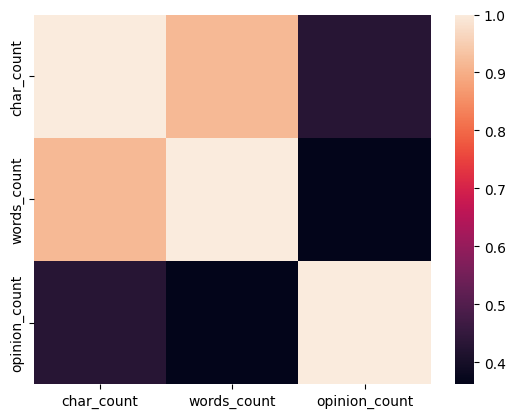

In [50]:
heatmap(phik_matrix(sentences_df_without_outliers[["char_count", "words_count", "opinion_count"]]))

In [51]:
phik_matrix(sentences_df_without_outliers[["char_count", "words_count", "opinion_count"]])

interval columns not set, guessing: ['char_count', 'words_count', 'opinion_count']


,char_count,words_count,opinion_count
char_count,1.000000,0.916455,0.428987
words_count,0.916455,1.000000,0.362300
opinion_count,0.428987,0.362300,1.000000


In [52]:
sentences_df["sentence_id"].duplicated().sum()

np.int64(0)

In [54]:
sentences_df["text"].duplicated().sum()

np.int64(0)

In [55]:
opinions_df.duplicated().sum()

np.int64(0)

In [61]:
sentences_df.isna().sum()

review_id        0
sentence_id      0
text             0
char_count       0
words_count      0
opinion_count    0
dtype: int64

In [63]:
sentences_df[(sentences_df["text"] == "") | sentences_df["text"] == " "].count()

review_id        0
sentence_id      0
text             0
char_count       0
words_count      0
opinion_count    0
dtype: int64

In [59]:
new_merged_df = pd.merge(opinions_df, sentences_df, how="left", on="sentence_id")
new_merged_df.isna().sum()

sentence_id         0
category            0
polarity            0
target              0
general_category    0
review_id           0
text                0
char_count          0
words_count         0
opinion_count       0
dtype: int64

In [60]:
new_merged_df = pd.merge(opinions_df, sentences_df, how="right", on="sentence_id")
new_merged_df.isna().sum()

sentence_id         0
category            9
polarity            9
target              9
general_category    9
review_id           0
text                0
char_count          0
words_count         0
opinion_count       0
dtype: int64

In [65]:
print(opinions_df["category"].nunique())
print(opinions_df["category"].unique())

11
['RESTAURANT#GENERAL' 'SERVICE#GENERAL' 'FOOD#QUALITY'
 'FOOD#STYLE_OPTIONS' 'AMBIENCE#GENERAL' 'RESTAURANT#PRICES' 'FOOD#PRICES'
 'LOCATION#GENERAL' 'DRINK#QUALITY' 'DRINK#PRICES' 'FOOD#GENERAL']


In [66]:
print(opinions_df["polarity"].nunique())
print(opinions_df["polarity"].unique())

3
['positive' 'neutral' 'negative']


In [ ]:
opinions_df[opinions_df["target"] == "NULL"].count()

sentence_id         15
category            15
polarity            15
target              15
general_category    15
dtype: int64